# 01 · MSFT next-day direction: features, baselines, walk-forward

**Question:** can simple models (logistic regression, XGBoost) predict MSFT's next-day direction
better than trivial baselines, **after transaction costs**?

> **TL;DR**
>
> - **No detectable predictive edge.** Pooled out-of-sample AUC is 0.506 (logistic regression) and 0.516 (XGBoost); both 95% intervals include 0.5 (0.484 to 0.526 and 0.496 to 0.535).
> - **Neither model beats buy-and-hold after 5 bps costs.** Net Sharpe is 0.93 and 0.84 against 0.94, and the Sharpe-difference intervals include 0 (-0.01 with CI -0.42 to 0.38; -0.10 with CI -0.45 to 0.26). Buy-and-hold returned +1,333% in total; the models returned +748% and +540%.
> - **What the models do buy is a smaller drawdown** (-31% and -33% against -37%), by sitting out 41% and 45% of days.
> - **Costs eat the signal:** at 0 bps the Sharpe point estimates (1.06 and 1.02) sit above buy-and-hold (0.94), and 5 bps removes the gap.
> - The test period is 2013-10 to 2026-05: 25 walk-forward folds, 3,150 days, including the 2018 sell-off, the 2020 crash and the 2022 bear market.

**Contents:** 1 Data · 2 Features · 3 Leakage check · 4 Baselines · 5 Walk-forward models ·
6 Results · 7 Robustness checks · 8 Findings

_Rule: every number that ends up on the resume must come from output in this notebook or from
`outputs/metrics.csv`. Prototype here, then move finished code into `src/stockpred/`._

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandas_ta_classic as ta
import yfinance as yf
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, NullFormatter
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# yfinance still calls pandas APIs that pandas 3.x deprecates; not ours to fix.
warnings.filterwarnings('ignore', message='The inplace keyword', module='yfinance')

# ---- Experiment settings: the single source of truth for every later cell ----
SEED = 42
START = '2010-01-01'
COST = 0.0005          # 5 bps per position change
TRADING_DAYS = 252
INITIAL_TRAIN = 756    # rows, ~3 years of first training data
TEST_SIZE = 126        # rows per test block, ~6 months
GAP = 5                # rows skipped between train and test, ~1 week
FEATURES = [
    'ret_1', 'ret_2', 'ret_5', 'ret_10', 'ret_21',
    'vol_5', 'vol_21', 'vol_63',
    'rsi_14', 'volume_z', 'dist_ma50', 'dist_ma200',
]

# ---- Plot style: models get the two strongest hues, baselines are recessive ----
COLORS = {
    'logreg': '#2a78d6', 'xgb': '#eb6834',
    'previous_day_direction': '#1baf7a', 'buy_and_hold': '#6b6a66',
}
LABELS = {
    'logreg': 'Logistic regression', 'xgb': 'XGBoost',
    'previous_day_direction': 'Previous-day direction', 'buy_and_hold': 'Buy and hold',
}
plt.rcParams.update({
    'figure.dpi': 110, 'axes.titlelocation': 'left', 'axes.titleweight': 'bold',
    'axes.titlesize': 11, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'grid.color': '#e8e7e2',
    'grid.linewidth': 0.6, 'lines.linewidth': 2, 'legend.frameon': False,
    'legend.fontsize': 9, 'axes.axisbelow': True,
})

## 1. Data

- **Stock: MSFT.** Liquid, long history, calmer than NVDA/TSLA, and different from the AAPL used in
  the KPI Anomaly Detection project. It is a hindsight pick, so results carry survivorship bias.
- Daily bars from 2010-01-01. yfinance returns split- and dividend-adjusted prices by default.
- Checks below: missing values, duplicates, zero-volume days, and a plot of the price (any
  split-sized jump would mean the data is unadjusted).

In [2]:
# The download is cached so every rerun sees identical prices. Without the cache, yfinance's
# adjusted history shifts slightly between calls (the adjustment moves with the latest bar),
# which changed XGBoost's results on identical code. Delete the file to refresh the data.
CACHE = Path('../data/msft.parquet')

if CACHE.exists():
    df = pd.read_parquet(CACHE)
else:
    raw = yf.Ticker('MSFT').history(start=START)
    # drop today's bar: during market hours it is still forming
    today = pd.Timestamp.now(tz=raw.index.tz).normalize()
    df = raw.loc[raw.index.normalize() < today]
    CACHE.parent.mkdir(exist_ok=True)
    df.to_parquet(CACHE)

print(f'{CACHE.name}: {len(df):,} bars through {df.index.max().date()}')
df.head()

msft.parquet: 4,232 bars through 2026-10-29


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2010-01-04 00:00:00-05:00,22.739173,23.095633,22.716894,22.984240,38409100,0.0,0.0
2010-01-05 00:00:00-05:00,22.909970,23.095626,22.754018,22.991657,49749600,0.0,0.0
2010-01-06 00:00:00-05:00,22.932258,23.080784,22.664914,22.850571,58182400,0.0,0.0
2010-01-07 00:00:00-05:00,22.746604,22.798588,22.419850,22.612932,50559700,0.0,0.0
2010-01-08 00:00:00-05:00,22.486682,22.932256,22.456976,22.768879,51197400,0.0,0.0


4,232 daily bars, 2010-01-04 to 2026-10-29


,MSFT
missing values,0
duplicate rows,0
zero-volume days,0
split rows in data,0
largest 1-day move,15.5%


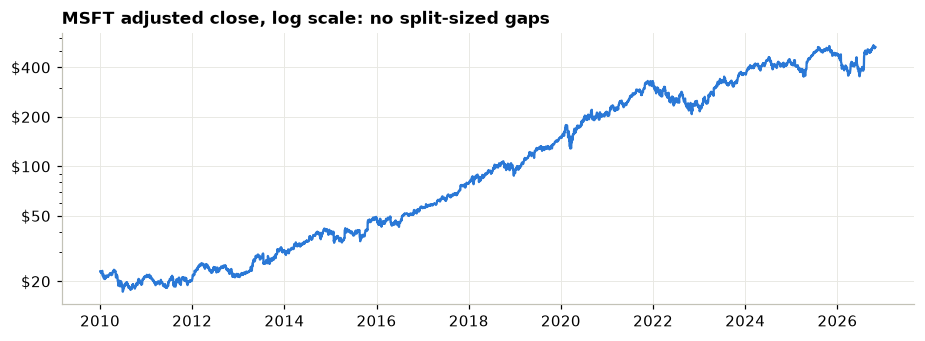

In [3]:
print(f'{len(df):,} daily bars, {df.index.min().date()} to {df.index.max().date()}')
quality = pd.Series({
    'missing values': int(df.isna().sum().sum()),
    'duplicate rows': int(df.duplicated().sum()),
    'zero-volume days': int((df['Volume'] == 0).sum()),
    'split rows in data': int((df['Stock Splits'] > 0).sum()),
    'largest 1-day move': f"{df['Close'].pct_change().abs().max():.1%}",
}, name='MSFT')
display(quality.to_frame())

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(df.index, df['Close'], color=COLORS['logreg'], linewidth=1.5)
ax.set_yscale('log')
ax.set_yticks([20, 50, 100, 200, 400])
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'${value:,.0f}'))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_title('MSFT adjusted close, log scale: no split-sized gaps')
plt.show()

## 2. Features and target

Rule: a feature on row *t* uses data up to the close of day *t* only.

- 12 features (the set is kept small: with ~4,000 rows, more features means more overfitting):
  lagged returns (1, 2, 5, 10, 21), rolling volatility (5, 21, 63), RSI(14), a trailing volume
  z-score, and distance from the 50- and 200-day moving averages.
- **Target:** 1 if the next day's return is positive, else 0. `next_return` is kept separately
  for the backtest.
- Warm-up rows (200-day window) and the final row (no next day) are dropped.

4,032 usable rows, 2010-10-18 to 2026-10-28
Class balance: 52.4% up days, 47.6% down days


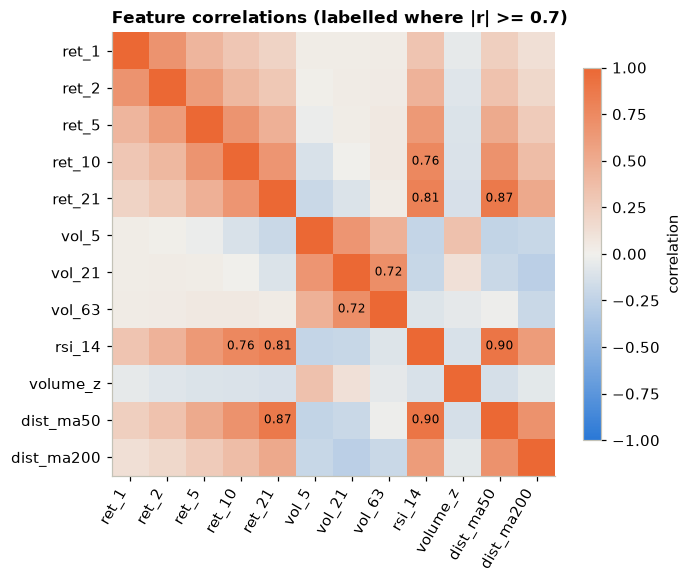

In [4]:
def build_features(raw: pd.DataFrame) -> pd.DataFrame:
    """Build features, next_return and target from raw OHLCV bars."""
    close = raw['Close']
    volume = raw['Volume']
    daily_return = close.pct_change()

    out = pd.DataFrame(index=raw.index)
    for lag in (1, 2, 5, 10, 21):
        out[f'ret_{lag}'] = close.pct_change(lag)
    for window in (5, 21, 63):
        out[f'vol_{window}'] = daily_return.rolling(window).std()
    out['rsi_14'] = ta.rsi(close, length=14)
    # trailing z-score: full-sample mean/std would leak future volume into past rows
    volume_z = (volume - volume.rolling(63).mean()) / volume.rolling(63).std()
    out['volume_z'] = volume_z.replace([np.inf, -np.inf], np.nan)
    out['dist_ma50'] = close / close.rolling(50).mean() - 1
    out['dist_ma200'] = close / close.rolling(200).mean() - 1

    out['next_return'] = daily_return.shift(-1)
    out['target'] = (out['next_return'] > 0).astype(float)
    out.loc[out['next_return'].isna(), 'target'] = np.nan  # last row has no next day
    return out


data = build_features(df).dropna(subset=FEATURES + ['next_return', 'target'])
data['target'] = data['target'].astype(int)
assert np.isfinite(data[FEATURES]).all().all(), 'features must be finite'

print(f'{data.shape[0]:,} usable rows, {data.index.min().date()} to {data.index.max().date()}')
print(f"Class balance: {data['target'].mean():.1%} up days, {1 - data['target'].mean():.1%} down days")

corr = data[FEATURES].corr()
diverging = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f1f0ec', '#eb6834'])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=60, ha='right')
ax.set_yticks(range(len(FEATURES)), FEATURES)
ax.grid(False)
for row in range(len(FEATURES)):
    for col in range(len(FEATURES)):
        if row != col and abs(corr.iloc[row, col]) >= 0.7:  # label only the strong pairs
            ax.text(col, row, f'{corr.iloc[row, col]:.2f}', ha='center', va='center', fontsize=8)
ax.set_title('Feature correlations (labelled where |r| >= 0.7)')
fig.colorbar(image, ax=ax, shrink=0.8, label='correlation')
plt.show()

## 3. Leakage check

Scramble every bar after a cutoff date and confirm that the features on rows up to the cutoff do not
change. Then confirm the labels are the only columns that look forward. This is written as a
function because it becomes the first pytest test.

In [5]:
def check_no_leakage(raw: pd.DataFrame, cutoff_pos: int = 2000, seed: int = SEED) -> None:
    """Scramble every bar after the cutoff; features on rows <= cutoff must not change."""
    rng = np.random.default_rng(seed)
    cutoff = raw.index[cutoff_pos]
    altered = raw[['Open', 'High', 'Low', 'Close', 'Volume']].astype(float)
    future = altered.index > cutoff
    altered.loc[future] = altered.loc[future].mul(rng.uniform(0.5, 2.0, future.sum()), axis=0)

    base = build_features(raw)
    new = build_features(altered)

    pd.testing.assert_frame_equal(base.loc[:cutoff, FEATURES], new.loc[:cutoff, FEATURES])
    # the check has power: the scrambled future must change the later features
    assert not base.loc[cutoff:, FEATURES].dropna().equals(new.loc[cutoff:, FEATURES].dropna())
    # the labels are the only look-ahead columns: they change on the cutoff row itself
    assert base.loc[cutoff, 'next_return'] != new.loc[cutoff, 'next_return']
    print(f'No leakage: {len(FEATURES)} features unchanged on rows <= {cutoff.date()}')


check_no_leakage(df)

No leakage: 12 features unchanged on rows <= 2017-12-12


## 4. Baselines

Walk-forward design: a ~3-year first training window, then consecutive ~6-month test blocks with an
expanding training window and a 5-row gap before each block. Blocks run **to the end of the data**,
so the test period includes the 2018 sell-off, the 2020 crash and the 2022 bear market.

Baselines are scored on exactly the same pooled test rows the models will use:
- **Buy and hold** (always up): accuracy ~ the up-fraction, AUC = 0.5.
- **Previous-day direction:** predict tomorrow = today.

Buy-and-hold on MSFT since 2010 is strong (survivorship), so a long/flat strategy that sits out part
of the time faces a high bar on raw return. Risk-adjusted numbers (Sharpe, drawdown) matter too.

In [6]:
def make_folds(n_rows: int) -> list[dict]:
    """Expanding-window folds, as many as fit. Train = rows [0, train_end), then GAP rows skipped."""
    n_folds = (n_rows - INITIAL_TRAIN - GAP) // TEST_SIZE
    folds = []
    for k in range(n_folds):
        test_start = INITIAL_TRAIN + GAP + k * TEST_SIZE
        folds.append({'fold': k, 'train_end': test_start - GAP,
                      'test_start': test_start, 'test_end': test_start + TEST_SIZE})
    return folds


def strategy_net(score: pd.Series, test: pd.DataFrame, cost: float = COST) -> pd.Series:
    """Long if score > 0.5 else flat; the position set at close t earns next_return."""
    position = (score > 0.5).astype(int)
    turnover = position.diff().abs().fillna(position.abs())  # first entry also pays the cost
    return position * test['next_return'] - cost * turnover


def sharpe(returns: pd.Series) -> float:
    return returns.mean() / returns.std() * np.sqrt(TRADING_DAYS)


def max_drawdown(returns: pd.Series) -> float:
    equity = (1 + returns).cumprod()
    return (equity / equity.cummax() - 1).min()


def summarize(name: str, score: pd.Series, test: pd.DataFrame) -> dict:
    net = strategy_net(score, test)
    position = (score > 0.5).astype(int)
    return {
        'name': name,
        'accuracy': (position == test['target']).mean(),
        'auc': roc_auc_score(test['target'], score),
        'net_sharpe': sharpe(net),
        'max_drawdown': max_drawdown(net),
        'total_return': (1 + net).prod() - 1,
        'trades': int(position.diff().abs().fillna(position).sum()),
        'time_in_market': position.mean(),
    }


folds = make_folds(len(data))
pooled_test = pd.concat([data.iloc[f['test_start']:f['test_end']] for f in folds])

baseline_scores = {
    'buy_and_hold': pd.Series(1.0, index=pooled_test.index),
    'previous_day_direction': (pooled_test['ret_1'] > 0).astype(float),
}
baselines = pd.DataFrame([summarize(name, score, pooled_test)
                          for name, score in baseline_scores.items()]).set_index('name')
print(f'{len(folds)} walk-forward folds, {len(pooled_test):,} pooled test rows '
      f'({pooled_test.index.min().date()} to {pooled_test.index.max().date()})')
baselines.round(4)

25 walk-forward folds, 3,150 pooled test rows (2013-10-25 to 2026-05-06)


,accuracy,auc,net_sharpe,max_drawdown,total_return,trades,time_in_market
name,,,,,,,
buy_and_hold,0.5308,0.5000,0.9382,-0.3715,13.3269,1,1.0000
previous_day_direction,0.4844,0.4825,-0.1227,-0.6547,-0.3854,1625,0.5308


## 5. Walk-forward models

- **Logistic regression** (scaler fit on the train window only) and **XGBoost** (shallow, regularised).
- Each fold trains on all data before the gap, predicts the next block, and records AUC, accuracy and
  feature importances.
- **Sanity checks** run in every fold: a model trained on a *shuffled* target should score AUC ~ 0.5,
  and an *oracle* that sees the answer should score exactly 1.0.
- Strategy: long if P(up) > 0.5, else flat; 5 bps charged on every position change.

In [7]:
def make_models() -> dict:
    return {
        # the scaler lives inside the pipeline, so it is fit on the train window only
        'logreg': make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000)),
        'xgb': XGBClassifier(
            n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.8,
            colsample_bytree=0.8, min_child_weight=10, reg_lambda=5.0,
            eval_metric='logloss', n_jobs=1, random_state=SEED,
        ),
    }


def fit_predict(model, x_train, y_train, x_test) -> np.ndarray:
    with warnings.catch_warnings():
        # numpy 2.2 on Apple Accelerate BLAS raises spurious matmul warnings on finite data
        # (verified: plain finite float64 matmul triggers them). Finiteness is asserted instead.
        warnings.filterwarnings('ignore', message='.*encountered in matmul', category=RuntimeWarning)
        model.fit(x_train, y_train)
        proba = model.predict_proba(x_test)[:, 1]
    assert np.isfinite(proba).all(), 'model produced non-finite probabilities'
    return proba


rng = np.random.default_rng(SEED)
parts, fold_rows, importance_rows = [], [], []
for f in folds:
    train = data.iloc[:f['train_end']]
    test = data.iloc[f['test_start']:f['test_end']]
    part = pd.DataFrame(index=test.index)

    for name, model in make_models().items():
        part[name] = fit_predict(model, train[FEATURES], train['target'], test[FEATURES])
        values = model[-1].coef_[0] if name == 'logreg' else model.feature_importances_
        importance_rows.append({'fold': f['fold'], 'model': name, **dict(zip(FEATURES, values))})

    # sanity checks: shuffled train target should give AUC ~ 0.5; oracle should give 1.0
    for name, model in make_models().items():
        shuffled = rng.permutation(train['target'].values)
        part[f'{name}_shuffled'] = fit_predict(model, train[FEATURES], shuffled, test[FEATURES])
    part['oracle'] = test['target'].astype(float)

    for column in part.columns:
        fold_rows.append({
            'fold': f['fold'], 'model': column,
            'auc': roc_auc_score(test['target'], part[column]),
            'accuracy': ((part[column] > 0.5).astype(int) == test['target']).mean(),
        })
    parts.append(part)

preds = pd.concat(parts)
assert preds.index.equals(pooled_test.index)
fold_scores = pd.DataFrame(fold_rows)
importances = pd.DataFrame(importance_rows)

pooled_scores = pd.DataFrame([{
    'model': column,
    'auc': roc_auc_score(pooled_test['target'], preds[column]),
    'accuracy': ((preds[column] > 0.5).astype(int) == pooled_test['target']).mean(),
} for column in preds.columns]).set_index('model')
assert pooled_scores.loc['oracle', 'auc'] == 1.0, 'oracle must score 1.0'
print('Pooled out-of-sample predictions')
pooled_scores.round(4)

Pooled out-of-sample predictions


,auc,accuracy
model,,
logreg,0.5061,0.5095
xgb,0.5159,0.5143
logreg_shuffled,0.4985,0.5140
xgb_shuffled,0.5113,0.5140
oracle,1.0000,1.0000


## 6. Results

Everything below is pooled out-of-sample and net of the 5 bps cost.

In [8]:
scores = {
    'buy_and_hold': baseline_scores['buy_and_hold'],
    'previous_day_direction': baseline_scores['previous_day_direction'],
    'logreg': preds['logreg'],
    'xgb': preds['xgb'],
}
metrics = pd.DataFrame([summarize(name, score, pooled_test)
                        for name, score in scores.items()]).set_index('name')
Path('../outputs').mkdir(exist_ok=True)
metrics.round(6).to_csv('../outputs/metrics.csv')
metrics.round(4)

,accuracy,auc,net_sharpe,max_drawdown,total_return,trades,time_in_market
name,,,,,,,
buy_and_hold,0.5308,0.5000,0.9382,-0.3715,13.3269,1,1.0000
previous_day_direction,0.4844,0.4825,-0.1227,-0.6547,-0.3854,1625,0.5308
logreg,0.5095,0.5061,0.9320,-0.3136,7.4848,659,0.5851
xgb,0.5143,0.5159,0.8363,-0.3341,5.4033,920,0.5473


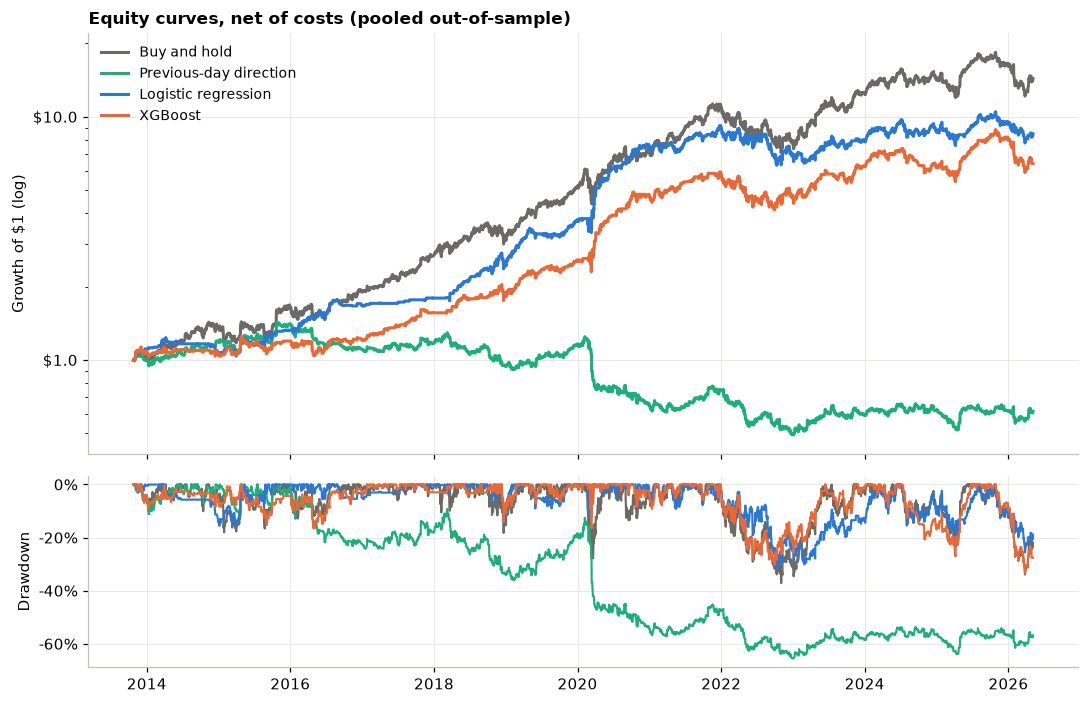

In [9]:
net_returns = {name: strategy_net(score, pooled_test) for name, score in scores.items()}

fig, (ax_equity, ax_dd) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True,
                                       gridspec_kw={'height_ratios': [2.2, 1]})
for name, net in net_returns.items():
    equity = (1 + net).cumprod()
    ax_equity.plot(equity.index, equity, color=COLORS[name], label=LABELS[name])
    ax_dd.plot(equity.index, equity / equity.cummax() - 1, color=COLORS[name], linewidth=1.4)
ax_equity.set_yscale('log')
ax_equity.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'${value:.1f}'))
ax_equity.yaxis.set_minor_formatter(NullFormatter())
ax_equity.set_ylabel('Growth of $1 (log)')
ax_equity.set_title('Equity curves, net of costs (pooled out-of-sample)')
ax_equity.legend(loc='upper left')
ax_dd.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:.0%}'))
ax_dd.set_ylabel('Drawdown')
fig.tight_layout()
plt.show()

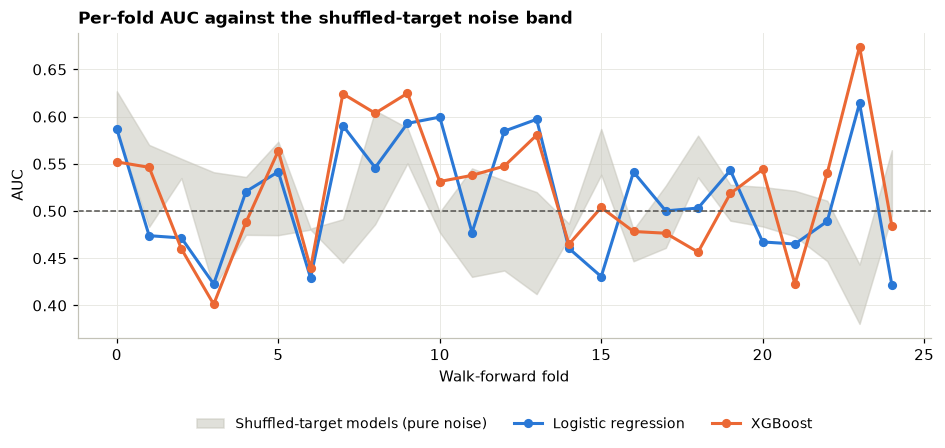

In [10]:
fold_auc = fold_scores.pivot(index='fold', columns='model', values='auc')
shuffled_cols = ['logreg_shuffled', 'xgb_shuffled']

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(fold_auc.index, fold_auc[shuffled_cols].min(axis=1),
                fold_auc[shuffled_cols].max(axis=1), color='#c3c2b7', alpha=0.5,
                label='Shuffled-target models (pure noise)')
for name in ('logreg', 'xgb'):
    ax.plot(fold_auc.index, fold_auc[name], color=COLORS[name], marker='o', markersize=5,
            label=LABELS[name])
ax.axhline(0.5, color='#52514e', linewidth=1, linestyle='--')
ax.set_xlabel('Walk-forward fold')
ax.set_ylabel('AUC')
ax.set_title('Per-fold AUC against the shuffled-target noise band')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3)
plt.show()

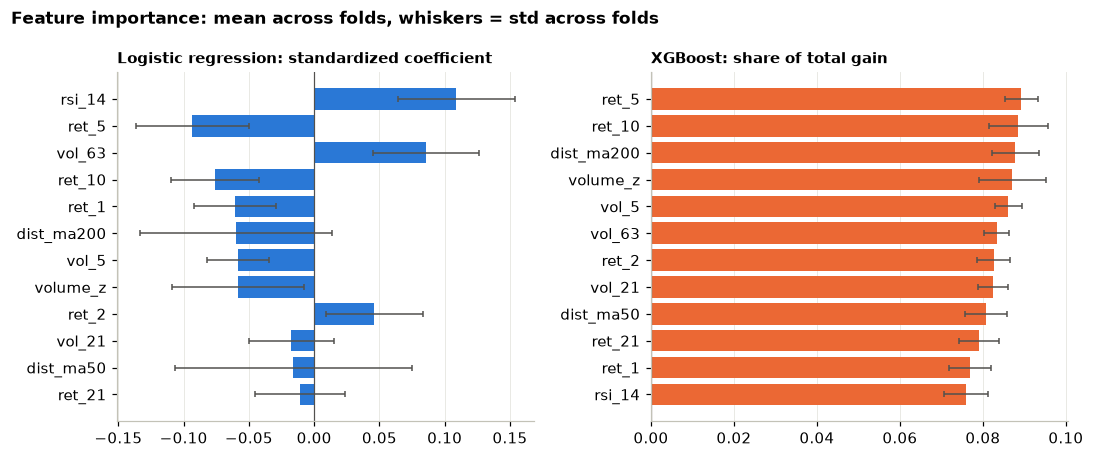

In [11]:
mean_importance = importances.groupby('model')[FEATURES].mean().T
std_importance = importances.groupby('model')[FEATURES].std().T

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
panels = [('logreg', 'Logistic regression: standardized coefficient'),
          ('xgb', 'XGBoost: share of total gain')]
for ax, (name, title) in zip(axes, panels):
    order = mean_importance[name].abs().sort_values().index
    ax.barh(order, mean_importance.loc[order, name], xerr=std_importance.loc[order, name],
            color=COLORS[name], error_kw={'ecolor': '#52514e', 'elinewidth': 1, 'capsize': 2})
    ax.axvline(0, color='#52514e', linewidth=0.8)
    ax.set_title(title, fontsize=10)
    ax.grid(axis='y', visible=False)
fig.suptitle('Feature importance: mean across folds, whiskers = std across folds',
             x=0.01, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout()
plt.show()

## 7. Robustness checks

1. **Bootstrap confidence intervals** (21-day blocks, keeps return autocorrelation).
2. **Timing-shift null:** keep each model's positions (same time in market, same number of trades)
   but slide them against the returns by a random offset. This destroys the timing and keeps the
   exposure, so it separates "good predictions" from "just being long part of the time".
3. **Cost sensitivity:** how fast the edge disappears as costs rise.
4. **Regimes:** performance above vs below the 200-day moving average (known at close *t*).

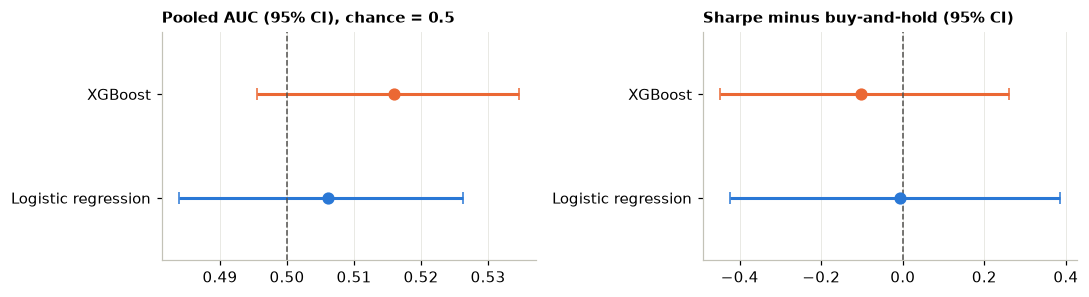

,estimate,ci_low,ci_high,excludes_0.5
metric,,,,
logreg pooled AUC,0.5061,0.4838,0.5262,False
xgb pooled AUC,0.5159,0.4956,0.5346,False
buy_and_hold net Sharpe,0.9382,0.4870,1.3849,NaN
previous_day_direction net Sharpe,-0.1227,-0.6883,0.4150,NaN
logreg net Sharpe,0.9320,0.4568,1.3810,NaN
xgb net Sharpe,0.8363,0.3667,1.3299,NaN
logreg Sharpe minus buy-and-hold,-0.0063,-0.4244,0.3849,NaN
xgb Sharpe minus buy-and-hold,-0.1019,-0.4486,0.2603,NaN


In [12]:
N_BOOT, BLOCK = 1000, 21  # moving-block bootstrap

boot_rng = np.random.default_rng(SEED)
n_rows = len(pooled_test)
target = pooled_test['target'].values
net_values = {name: net.values for name, net in net_returns.items()}


def block_sample(n: int) -> np.ndarray:
    n_blocks = int(np.ceil(n / BLOCK))
    starts = boot_rng.integers(0, n - BLOCK + 1, n_blocks)
    return (starts[:, None] + np.arange(BLOCK)).ravel()[:n]


def sharpe_values(values: np.ndarray) -> float:
    return values.mean() / values.std(ddof=1) * np.sqrt(TRADING_DAYS)


auc_draws = {name: [] for name in ('logreg', 'xgb')}
sharpe_draws = {name: [] for name in net_values}
for _ in range(N_BOOT):
    idx = block_sample(n_rows)
    for name in auc_draws:
        auc_draws[name].append(roc_auc_score(target[idx], preds[name].values[idx]))
    for name, values in net_values.items():
        sharpe_draws[name].append(sharpe_values(values[idx]))

rows = []
for name, draws in auc_draws.items():
    low, high = np.percentile(draws, [2.5, 97.5])
    rows.append({'metric': f'{name} pooled AUC', 'estimate': pooled_scores.loc[name, 'auc'],
                 'ci_low': low, 'ci_high': high, 'excludes_0.5': bool(low > 0.5 or high < 0.5)})
for name, draws in sharpe_draws.items():
    low, high = np.percentile(draws, [2.5, 97.5])
    rows.append({'metric': f'{name} net Sharpe', 'estimate': metrics.loc[name, 'net_sharpe'],
                 'ci_low': low, 'ci_high': high, 'excludes_0.5': np.nan})
for name in ('logreg', 'xgb'):
    diff = np.array(sharpe_draws[name]) - np.array(sharpe_draws['buy_and_hold'])
    low, high = np.percentile(diff, [2.5, 97.5])
    rows.append({'metric': f'{name} Sharpe minus buy-and-hold',
                 'estimate': metrics.loc[name, 'net_sharpe'] - metrics.loc['buy_and_hold', 'net_sharpe'],
                 'ci_low': low, 'ci_high': high, 'excludes_0.5': np.nan})
ci_table = pd.DataFrame(rows).set_index('metric')

fig, (ax_auc, ax_diff) = plt.subplots(1, 2, figsize=(10, 2.8))
for ax, keys, reference, title in [
    (ax_auc, ['logreg pooled AUC', 'xgb pooled AUC'], 0.5, 'Pooled AUC (95% CI), chance = 0.5'),
    (ax_diff, ['logreg Sharpe minus buy-and-hold', 'xgb Sharpe minus buy-and-hold'], 0.0,
     'Sharpe minus buy-and-hold (95% CI)'),
]:
    for position, key in enumerate(keys):
        name = key.split()[0]
        row = ci_table.loc[key]
        ax.errorbar(row['estimate'], position, xerr=[[row['estimate'] - row['ci_low']],
                                                     [row['ci_high'] - row['estimate']]],
                    fmt='o', color=COLORS[name], markersize=7, capsize=4)
    ax.axvline(reference, color='#52514e', linewidth=1, linestyle='--')
    ax.set_yticks(range(len(keys)), [LABELS[key.split()[0]] for key in keys])
    ax.set_ylim(-0.6, len(keys) - 0.4)
    ax.grid(axis='y', visible=False)
    ax.set_title(title, fontsize=10)
fig.tight_layout()
plt.show()
ci_table.round(4)

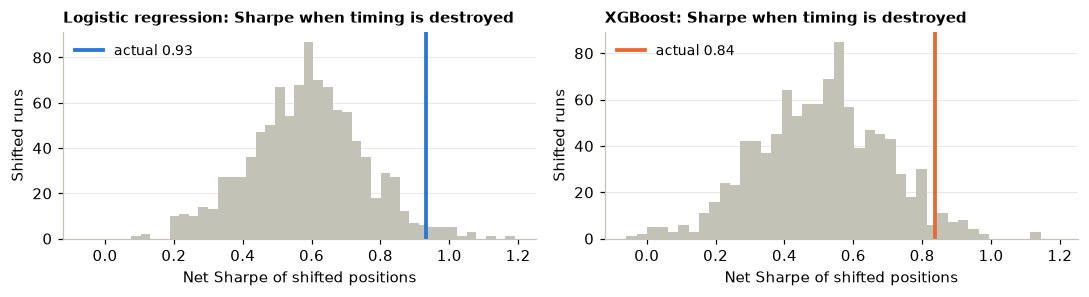

,actual net Sharpe,null median,null 95th pct,p-value (one-sided)
logreg,0.9320,0.5913,0.8479,0.025
xgb,0.8363,0.5148,0.8040,0.035


In [13]:
N_SHIFT = 1000
shift_rng = np.random.default_rng(SEED)
next_return = pooled_test['next_return'].values


def shifted_sharpe_null(score: pd.Series) -> np.ndarray:
    """Sharpe of the same positions slid against the returns by a random offset."""
    position = (score > 0.5).astype(int).values
    draws = []
    for shift in shift_rng.integers(BLOCK, len(position) - BLOCK, N_SHIFT):
        shifted = np.roll(position, shift)
        turnover = np.abs(np.diff(shifted, prepend=0))
        net = shifted * next_return - COST * turnover
        draws.append(net.mean() / net.std(ddof=1) * np.sqrt(TRADING_DAYS))
    return np.array(draws)


null_draws = {name: shifted_sharpe_null(scores[name]) for name in ('logreg', 'xgb')}
null_table = pd.DataFrame({
    name: {
        'actual net Sharpe': metrics.loc[name, 'net_sharpe'],
        'null median': np.median(draws),
        'null 95th pct': np.percentile(draws, 95),
        'p-value (one-sided)': (draws >= metrics.loc[name, 'net_sharpe']).mean(),
    } for name, draws in null_draws.items()
}).T

fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharex=True)
for ax, (name, draws) in zip(axes, null_draws.items()):
    ax.hist(draws, bins=40, color='#c3c2b7')
    ax.axvline(metrics.loc[name, 'net_sharpe'], color=COLORS[name], linewidth=2.5,
               label=f'actual {metrics.loc[name, "net_sharpe"]:.2f}')
    ax.set_title(f'{LABELS[name]}: Sharpe when timing is destroyed', fontsize=10)
    ax.set_xlabel('Net Sharpe of shifted positions')
    ax.set_ylabel('Shifted runs')
    ax.legend(loc='upper left')
    ax.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()
null_table.round(4)

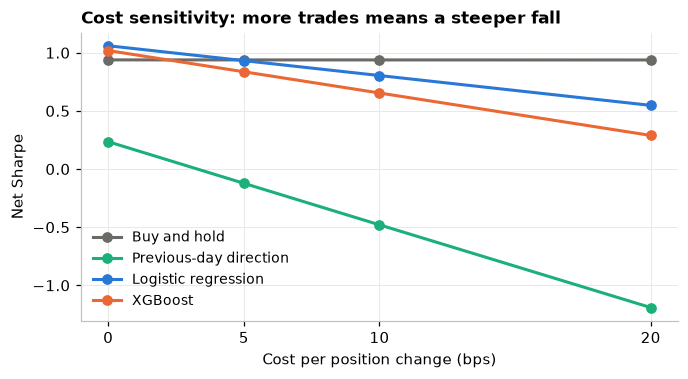

,0 bps,5 bps,10 bps,20 bps
Buy and hold,0.938,0.938,0.938,0.938
Previous-day direction,0.235,-0.123,-0.480,-1.191
Logistic regression,1.060,0.932,0.804,0.547
XGBoost,1.019,0.836,0.654,0.289


In [14]:
COSTS_BPS = [0, 5, 10, 20]
cost_table = pd.DataFrame({
    LABELS[name]: {f'{bps} bps': sharpe(strategy_net(score, pooled_test, cost=bps / 1e4))
                   for bps in COSTS_BPS}
    for name, score in scores.items()
}).T

fig, ax = plt.subplots(figsize=(7, 3.4))
for name, score in scores.items():
    ax.plot(COSTS_BPS, cost_table.loc[LABELS[name]].values, color=COLORS[name], marker='o',
            markersize=6, label=LABELS[name])
ax.set_xticks(COSTS_BPS)
ax.set_xlabel('Cost per position change (bps)')
ax.set_ylabel('Net Sharpe')
ax.set_title('Cost sensitivity: more trades means a steeper fall')
ax.legend(loc='lower left')
plt.show()
cost_table.round(3)

In [15]:
in_uptrend = (pooled_test['dist_ma200'] > 0).values
regime_names = {True: 'above 200d MA', False: 'below 200d MA'}
regime_rows = []
for name, score in scores.items():
    net = net_returns[name]  # computed on the full pooled period, then sliced by regime
    for flag, regime in regime_names.items():
        mask = in_uptrend == flag
        regime_rows.append({
            'strategy': LABELS[name], 'regime': regime, 'days': int(mask.sum()),
            'net_sharpe': sharpe(net[mask]),
            'auc': roc_auc_score(target[mask], score.values[mask]),
        })
regime_table = pd.DataFrame(regime_rows).pivot(index='strategy', columns='regime',
                                               values=['net_sharpe', 'auc'])
print({regime: int((in_uptrend == flag).sum()) for flag, regime in regime_names.items()},
      'test days per regime')
regime_table.round(3)

{'above 200d MA': 2591, 'below 200d MA': 559} test days per regime


net_sharpe                         auc              
regime                 above 200d MA below 200d MA above 200d MA below 200d MA
strategy                                                                      
Buy and hold                   0.829         1.335         0.500         0.500
Logistic regression            0.832         1.312         0.516         0.473
Previous-day direction        -0.141        -0.058         0.478         0.502
XGBoost                        0.793         1.078         0.526         0.478

## 8. Findings

_Numbers below come from the cached data through 2026-10-29 (`data/msft.parquet`). Delete that file to refresh the download, then rerun and update this section._

**Did either model beat the baselines in pooled AUC?** Barely, and not detectably. Always-up scores 0.500 and previous-day direction 0.48. Logistic regression reaches 0.506 and XGBoost 0.516, which is +0.006 and +0.016 over chance. Both intervals include 0.5. The shuffled-target models score 0.499 and 0.511, so XGBoost's 0.516 is only about 0.005 above what a model trained on noise achieves. The per-fold AUCs move in and out of the shuffled-target band with no consistent pattern.

**What happened to the edge after costs, and against buy-and-hold?** After 5 bps per position change, net Sharpe is 0.93 (logistic regression) and 0.84 (XGBoost), against 0.94 for buy-and-hold. Total return is +748% and +540% against +1,333%. Max drawdown improves from -37% to -31% and -33%, because the models are out of the market 41% and 45% of the time. At 0 bps the models' Sharpe is 1.06 and 1.02, so the costs of 659 and 920 trades erase the gross edge. At 20 bps the Sharpe falls to 0.55 and 0.29.

The timing-shift check gives a mildly positive signal: sliding each model's positions against the returns gives a median Sharpe of 0.59 (logistic regression) and 0.51 (XGBoost), and the actual 0.93 and 0.84 beat all but 2.5% and 3.5% of shifted runs. That is weak evidence, since two models were tested without correction and the shifted positions are autocorrelated, which makes the p-values approximate. It also does not translate into beating buy-and-hold.

**Which features mattered?** Logistic regression leans on `rsi_14` (positive) and the short-horizon returns `ret_1`, `ret_5`, `ret_10` (negative), a short-term reversal pattern, plus `vol_63` (positive). The signs of `dist_ma50`, `dist_ma200`, `vol_21` and `ret_21` are unstable across folds, since their whiskers cross zero. XGBoost spreads its gain almost evenly (0.076 to 0.089 per feature), so no feature dominates, which fits a model fitting noise. SHAP is the next step if this goes further.

**Regimes.** Above the 200-day average (2,591 test days) the AUCs are 0.516 and 0.526. Below it (559 days) they are 0.473 and 0.478. With only 559 days, I would not read that as a pattern. Neither model meaningfully beats buy-and-hold on Sharpe in either regime: logistic regression ties it above the average (0.832 against 0.829) and trails slightly below it (1.312 against 1.335), and XGBoost trails in both.

**Limits.**
- One stock, chosen with hindsight; MSFT's 2010-2026 run is a strong bull market, so buy-and-hold is a hard bar.
- One cost assumption (5 bps per position change). Bid-ask spread, slippage and taxes are not modelled; the sensitivity table shows the direction of travel.
- Daily bars only, and long/flat positions only.
- 3,150 test days is a small sample for Sharpe ratios; the intervals are wide.
- Model hyperparameters were fixed up front and not tuned, which keeps the test honest but leaves possible gains on the table.
- Small data revisions matter. In testing, two downloads of the same history differed by a few hundredths of a percent in adjusted price, enough to change trade counts and move XGBoost's Sharpe by a few hundredths. Sharpe gaps of that size between a model and buy-and-hold are noise, which is why the notebook caches its data.

**Bottom line:** simple models on daily MSFT features are indistinguishable from chance on AUC, and they do not beat buy-and-hold after costs. They trade some return for a smaller drawdown.